# Building Perceptron — Partie 1 : du Deep Learning au neurone artificiel



**Auteur :** Dehlia Neiss — La Plateforme
**Périmètre de ce notebook :** sections « Initiation au Deep Learning » et « Dessine-moi un neurone artificiel » du sujet. L'application au jeu de données *Breast Cancer Wisconsin* fera l'objet de la partie suivante.

## Introduction

L'objectif de ce notebook est de comprendre, puis de **reconstruire à la main**, le tout premier neurone artificiel : le **Perceptron** de Frank Rosenblatt (1958).

Le notebook suit la démarche suivante :

1. **Initiation au Deep Learning** : définir le Machine Learning et le Deep Learning, les comparer, savoir quand utiliser l'un ou l'autre, puis présenter trois applications concrètes.
2. **Dessine-moi un neurone artificiel** : répondre aux questions théoriques (définition, équation, règle d'apprentissage, activation, entraînement, limites).
3. **Implémentation** : développer une classe `Perceptron` en programmation orientée objet (fichier `perceptron.py`) et la tester sur des **données factices générées aléatoirement**.
4. **Conclusion** et transition vers l'application sur des données réelles.

Seules deux bibliothèques sont utilisées pour le code : **NumPy** (calcul) et **Matplotlib** (visualisation). Le Perceptron est codé *from scratch*, sans scikit-learn, pour bien comprendre chaque ligne.

## Sommaire

1. [Initiation au Deep Learning](#1.-Initiation-au-Deep-Learning)
   - 1.1 Machine Learning
   - 1.2 Deep Learning
   - 1.3 Comparaison et choix
   - 1.4 Trois applications du Deep Learning
2. [Dessine-moi un neurone artificiel](#2.-Dessine-moi-un-neurone-artificiel)
   - Q1 à Q6 : théorie du Perceptron
   - Q7 : implémentation Python orientée objet et tests sur données factices
3. [Conclusion](#3.-Conclusion)
4. [Bibliographie](#4.-Bibliographie)

---
# 1. Initiation au Deep Learning

## 1.1 Le Machine Learning (apprentissage automatique)

Le **Machine Learning** est une branche de l'intelligence artificielle dans laquelle un programme **apprend des régularités à partir de données** au lieu d'être programmé règle par règle. Une fois entraîné, le modèle peut faire des **prédictions ou des décisions sur des données nouvelles**

Concrètement, au lieu d'écrire `si taille > 15 mm alors tumeur maligne`, on fournit au programme des exemples déjà étiquetés et c'est l'algorithme qui trouve la règle.

On distingue généralement trois grandes familles :

| Famille | Principe | Exemple |
|---|---|---|
| **Supervisé** | On apprend à partir d'exemples étiquetés (entrée → bonne réponse) | Prédire si un e-mail est un spam |
| **Non supervisé** | On cherche une structure dans des données sans étiquette | Regrouper des clients en segments |
| **Par renforcement** | Un agent apprend par essais / erreurs grâce à des récompenses | Apprendre à jouer à un jeu |

Exemples d'algorithmes « classiques » : régression linéaire / logistique, arbres de décision, forêts aléatoires, SVM, k plus proches voisins… et **le Perceptron**, qui est à la frontière entre ML classique et Deep Learning.

Point essentiel : en ML classique, c'est souvent **l'humain qui choisit et construit les variables** (*feature engineering*) que le modèle va utiliser 

## 1.2 Le Deep Learning (apprentissage profond)

Le **Deep Learning** est un **sous-domaine du Machine Learning** qui repose sur des **réseaux de neurones artificiels composés de nombreuses couches** — d'où le terme « profond »

Chaque couche transforme les données reçues de la couche précédente : les premières couches détectent des motifs simples (bords d'une image, sons élémentaires), les suivantes les combinent en concepts de plus en plus abstraits (formes, objets, mots).

Sa grande force : il peut travailler sur des **données brutes et non structurées** (images, texte, son) et **extrait lui-même les caractéristiques utiles**, ce qui réduit fortement le travail manuel de *feature engineering* .

Sa contrepartie : il demande **beaucoup de données et de puissance de calcul** (GPU), et ses décisions sont **plus difficiles à interpréter** 

L'emboîtement des notions peut se résumer ainsi :

```
Intelligence Artificielle
 └── Machine Learning
      └── Réseaux de neurones
           └── Deep Learning (réseaux à plusieurs couches cachées)
```

## 1.3 Comparaison et choix entre ML et DL

| Critère | Machine Learning « classique » | Deep Learning |
|---|---|---|
| **Type de données** | Données **structurées**, tabulaires (tableaux, CSV, bases SQL) | Données **non structurées** : images, texte, audio, vidéo |
| **Variables (features)** | Choisies / construites par l'humain | Apprises automatiquement par le réseau |
| **Volume de données** | Fonctionne avec des volumes modestes | Nécessite de très grands volumes |
| **Puissance de calcul** | Un CPU suffit souvent | GPU / clusters souvent nécessaires |
| **Temps d'entraînement** | Court (secondes à minutes) | Long (heures à semaines) |
| **Interprétabilité** | Bonne (on peut souvent expliquer la décision) | Faible (« boîte noire ») |
| **Coût** | Faible | Élevé (infrastructure, énergie) |


### Quand utiliser l'un plutôt que l'autre ?

**Privilégier le Machine Learning classique quand :**
- les données sont **tabulaires** et de taille raisonnable (quelques centaines à quelques milliers de lignes) ;
- on a besoin d'**expliquer la décision** (santé, banque, juridique) ;
- les ressources (temps, calcul, budget) sont limitées ;
- la tâche est bien définie (ex. : détection de spam, prédiction de désabonnement client). Pour ce type de tâche simple, le ML classique est souvent aussi bon, voire meilleur 
**Privilégier le Deep Learning quand :**
- les données sont **non structurées** (images médicales, voix, texte libre) ;
- on dispose d'un **grand volume de données** étiquetées (ou de modèles pré-entraînés réutilisables) ;
- les relations à capturer sont **très complexes** et difficiles à décrire à la main (reconnaissance d'images, traduction, génération de texte) ;
- on dispose de la puissance de calcul nécessaire.

**Règle pratique :** on commence toujours par le modèle le plus simple qui peut fonctionner. Si un modèle classique atteint de bonnes performances, il n'est pas utile de passer au Deep Learning. C'est d'ailleurs ce que nous ferons dans la suite du projet : tester un modèle simple (le Perceptron) sur des données tabulaires.

## 1.4 Trois applications du Deep Learning

### Application 1 — Vision : *Quick, Draw!* (Google AI Experiments)

*Quick, Draw!* est un jeu de la collection [AI Experiments de Google](https://experiments.withgoogle.com/collection/ai) : l'utilisateur dessine un objet en 20 secondes et **un réseau de neurones essaie de deviner ce qui est dessiné** ([Experiments with Google — Quick, Draw!](https://experiments.withgoogle.com/quick-draw)).

- **Données :** les dessins des joueurs ; Google a rendu public un jeu de **50 millions de dessins** ([Quick, Draw! The Data](https://quickdraw.withgoogle.com/data)).
- **Pourquoi du Deep Learning :** un dessin à main levée est une donnée non structurée, très variable d'une personne à l'autre ; impossible d'écrire des règles à la main.
- **Prolongement :** ces dessins ont servi à entraîner *Sketch-RNN*, un réseau récurrent capable de **terminer un dessin commencé** ([Experiments with Google — Sketch-RNN](https://experiments.withgoogle.com/sketch-rnn-demo)).

### Application 2 — Audio et langage : *Whisper* (OpenAI)

*Whisper* est un système de **reconnaissance automatique de la parole** développé par OpenAI ([OpenAI — Introducing Whisper](https://openai.com/index/whisper/)).

- **Données :** **680 000 heures** d'audio multilingue collectées sur le web.
- **Architecture :** un *Transformer* encodeur-décodeur ; l'audio est découpé en morceaux de 30 secondes, transformé en spectrogramme, puis converti en texte.
- **Usages :** transcription de réunions, sous-titrage, interfaces vocales, traduction de la parole vers l'anglais.

### Application 3 — Santé et science : *AlphaFold* (DeepMind)

*AlphaFold* prédit la **structure 3D d'une protéine** à partir de sa seule séquence d'acides aminés, un problème ouvert depuis plus de 50 ans 

- **Résultat :** lors de la compétition CASP14, AlphaFold atteint une précision **comparable aux méthodes expérimentales** dans la majorité des cas.
- **Impact :** la revue *Nature Methods* a désigné la prédiction de structure des protéines « Méthode de l'année 2021 » ([Nature Methods](https://www.nature.com/articles/s41592-021-01380-4)), et la base AlphaFold contient aujourd'hui **environ 200 millions de structures prédites**
- **Lien avec notre projet :** c'est un exemple de Deep Learning appliqué à la **santé**, comme le sera (avec un modèle beaucoup plus simple) notre étude sur le cancer du sein.

---
# 2. Dessine-moi un neurone artificiel

## Q1. Qu'est-ce qu'un Perceptron ? Quel est le lien avec un neurone biologique ?

Le **Perceptron** est le **premier modèle de neurone artificiel capable d'apprendre**, proposé par le psychologue **Frank Rosenblatt** en 1958 au Cornell Aeronautical Laboratory Contrairement au neurone formel de McCulloch et Pitts (1943), dont les connexions étaient fixes, le Perceptron **ajuste lui-même ses poids** à partir de ses erreurs 

C'est un **classifieur binaire linéaire** : il reçoit plusieurs valeurs en entrée et répond par **0 ou 1** (par exemple « bénin » / « malin »).

### Analogie avec le neurone biologique

| Neurone biologique | Perceptron |
|---|---|
| **Dendrites** : reçoivent les signaux d'autres neurones | **Entrées** $x_1, x_2, \dots, x_n$ |
| **Synapses** : renforcent ou atténuent chaque signal | **Poids** $w_1, w_2, \dots, w_n$ |
| **Corps cellulaire (soma)** : additionne les signaux reçus | **Somme pondérée** $\sum w_i x_i + b$ |
| **Seuil d'excitation** : le neurone ne « s'active » que si le signal total est suffisant | **Biais** $b$ + **fonction d'activation** (seuil) |
| **Axone** : transmet (ou non) un potentiel d'action, en « tout ou rien » | **Sortie** $\hat{y} \in \{0, 1\}$ |
| **Plasticité synaptique** : les connexions utiles se renforcent avec l'expérience | **Règle d'apprentissage** : mise à jour des poids |

Le Perceptron est une **simplification extrême** : un vrai neurone a un comportement temporel, chimique et bien plus complexe. Mais l'idée centrale est conservée : **combiner des signaux pondérés et ne réagir qu'au-delà d'un seuil**.



## Q2. Fonction mathématique du Perceptron et usage

Le Perceptron calcule sa sortie en **deux étapes**.

**Étape 1 — Somme pondérée (ou « entrée nette ») :**

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^\top \mathbf{x} + b$$

**Étape 2 — Activation (seuil) :**

$$\hat{y} = f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

### Définition des termes

| Terme | Nom | Rôle |
|---|---|---|
| $x_i$ | **Entrée** (variable, *feature*) | Une caractéristique de l'exemple (ex. : rayon d'un noyau cellulaire) |
| $n$ | Nombre d'entrées | Nombre de variables décrivant un exemple |
| $w_i$ | **Poids** | Importance accordée à l'entrée $x_i$. Un poids positif pousse vers la classe 1, un poids négatif vers la classe 0 |
| $b$ | **Biais** | Décale le seuil de décision ; permet à la frontière de ne pas passer par l'origine. Équivaut à $-\theta$ (seuil) |
| $z$ | **Entrée nette** | Score brut du neurone |
| $f$ | **Fonction d'activation** | Transforme le score en décision (ici, une marche) |
| $\hat{y}$ | **Sortie prédite** | Classe prédite : 0 ou 1 |
| $y$ | **Étiquette réelle** | La bonne réponse, utilisée pendant l'entraînement |

### Interprétation géométrique et usage

L'équation $\mathbf{w}^\top \mathbf{x} + b = 0$ définit un **hyperplan** (une droite en 2D, un plan en 3D). Le Perceptron sépare l'espace en **deux demi-espaces** : d'un côté la classe 1, de l'autre la classe 0.

**Usage :** la **classification binaire de données linéairement séparables** (ex. : spam / non-spam, bénin / malin, portes logiques AND / OR). C'est aussi la **brique de base** des réseaux de neurones multicouches.

## Q3. Règle(s) d'apprentissage du Perceptron

### Règle de Rosenblatt (règle du Perceptron)

Pour chaque exemple $(\mathbf{x}, y)$ du jeu d'entraînement :

1. on calcule la prédiction $\hat{y}$ ;
2. on calcule l'erreur $e = y - \hat{y}$, qui vaut **−1, 0 ou +1** ;
3. on corrige les poids et le biais :

$$w_i \leftarrow w_i + \eta \,(y - \hat{y})\, x_i \qquad\qquad b \leftarrow b + \eta\,(y - \hat{y})$$

où $\eta$ (*eta*) est le **taux d'apprentissage** (*learning rate*), un petit nombre positif (ex. : 0,01 ou 0,1).

**Lecture intuitive des trois cas :**

| Cas | Erreur $y - \hat{y}$ | Effet |
|---|---|---|
| Bonne prédiction | 0 | Aucun changement |
| Le neurone a répondu 0 au lieu de 1 | +1 | Les poids **augmentent** dans la direction de $\mathbf{x}$ → $z$ augmentera la prochaine fois |
| Le neurone a répondu 1 au lieu de 0 | −1 | Les poids **diminuent** dans la direction de $\mathbf{x}$ → $z$ diminuera la prochaine fois |

Le Perceptron **n'apprend que de ses erreurs**.

### Autres règles liées

- **Règle de Hebb (1949)** : « des neurones qui s'activent ensemble se connectent ensemble » : $\Delta w_i = \eta \, x_i \, y$. Elle a inspiré Rosenblatt, mais n'utilise pas d'erreur.
- **Règle Delta / Widrow-Hoff (ADALINE, 1960)** : on corrige à partir de l'erreur **continue** $y - z$ (avant le seuil), ce qui revient à minimiser l'erreur quadratique par **descente de gradient** :

$$J(\mathbf{w}) = \frac{1}{2}\sum_{k}\big(y^{(k)} - z^{(k)}\big)^2 \quad\Rightarrow\quad w_i \leftarrow w_i - \eta\,\frac{\partial J}{\partial w_i} = w_i + \eta \sum_k \big(y^{(k)} - z^{(k)}\big)\,x_i^{(k)}$$

Cette idée de descente de gradient est celle qui, généralisée par la **rétropropagation**, permet d'entraîner les réseaux profonds 

### Théorème de convergence

Si les données sont **linéairement séparables**, la règle du Perceptron **converge en un nombre fini d'itérations** vers une frontière qui sépare parfaitement les deux classes (théorème de convergence de Novikoff, 1962). Si elles ne le sont pas, l'algorithme **ne s'arrête jamais de lui-même** : les poids oscillent.

## Q4. Quelle fonction d'activation ?

Le Perceptron utilise la **fonction de Heaviside** (fonction « marche » ou « échelon », *step function*) :

$$H(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

Une variante équivalente est la **fonction signe**, qui renvoie **+1 / −1** au lieu de 1 / 0.

**Caractéristiques :**
- elle produit une décision **binaire, en « tout ou rien »**, comme le potentiel d'action d'un neurone biologique ;
- elle n'est **pas dérivable en 0** et sa dérivée vaut 0 partout ailleurs. On ne peut donc pas l'utiliser avec la descente de gradient. C'est pour cela que les réseaux modernes la remplacent par des fonctions **continues** : sigmoïde, tanh, ReLU.

Le graphique ci-dessous compare la fonction de Heaviside à la sigmoïde (sa version « lissée »).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from perceptron import Perceptron  # notre classe, définie dans perceptron.py

# Style des graphiques
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
from matplotlib.ticker import MaxNLocator
BLEU, ORANGE, GRIS = "#0060FF", "#E8710A", "#6B6B6B"

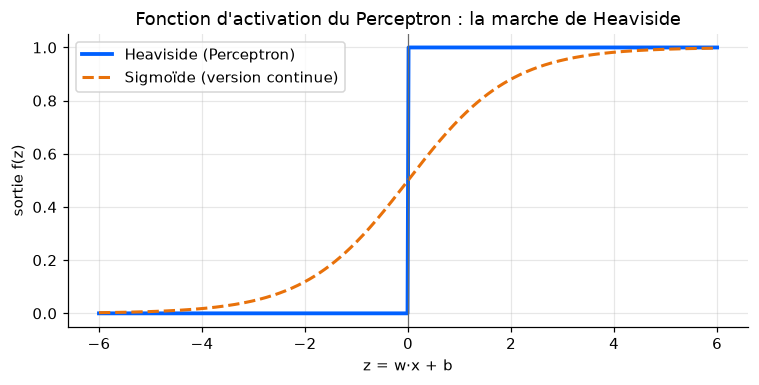

In [ ]:
z = np.linspace(-6, 6, 600)
heaviside = np.where(z >= 0, 1, 0)
sigmoide = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(z, heaviside, color=BLEU, lw=2.5, label="Heaviside (Perceptron)")
ax.plot(z, sigmoide, color=ORANGE, lw=2, ls="--", label="Sigmoïde (version continue)")
ax.axvline(0, color=GRIS, lw=0.8)
ax.set_xlabel("z = w·x + b")
ax.set_ylabel("sortie f(z)")
ax.set_title("Fonction d'activation du Perceptron : la marche de Heaviside")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("images/activation_heaviside.png", dpi=150)
plt.show()

**Interprétation :** la marche de Heaviside « saute » brutalement de 0 à 1 lorsque $z$ franchit 0 : le neurone est soit éteint, soit allumé. La sigmoïde fait la même transition de façon progressive, ce qui la rend dérivable et donc compatible avec la descente de gradient.

## Q5. Processus d'entraînement du Perceptron

L'entraînement suit un **algorithme itératif** :

1. **Préparer les données** : variables $X$ et étiquettes $y \in \{0, 1\}$. Il est conseillé de **standardiser** les variables (moyenne 0, écart-type 1) pour qu'aucune ne domine les autres uniquement à cause de son échelle.
2. **Initialiser** les poids $\mathbf{w}$ à 0 ou à de petites valeurs aléatoires, et le biais $b$ à 0.
3. **Pour chaque époque** (un passage complet sur les données) :
   - (optionnel) **mélanger** l'ordre des exemples ;
   - **pour chaque exemple** $(\mathbf{x}, y)$ :
     1. calculer $z = \mathbf{w}^\top\mathbf{x} + b$ ;
     2. prédire $\hat{y} = H(z)$ ;
     3. calculer l'erreur $y - \hat{y}$ ;
     4. mettre à jour $\mathbf{w}$ et $b$ avec la règle de Rosenblatt.
   - compter le **nombre d'erreurs** de l'époque.
4. **Arrêter** lorsque :
   - une époque se termine **sans aucune erreur** (convergence), **ou**
   - le **nombre maximal d'époques** est atteint (indispensable si les données ne sont pas séparables).
5. **Évaluer** le modèle sur des données **qu'il n'a jamais vues** (jeu de test) pour mesurer sa capacité de généralisation.

```
            ┌──────────────────────────────────────────────┐
            │  Initialiser w ≈ 0, b = 0                     │
            └───────────────────────┬──────────────────────┘
                                    ▼
      ┌──────────────► pour chaque exemple (x, y) ──────────────┐
      │                z = w·x + b → ŷ = H(z) → erreur = y − ŷ   │
      │                w += η·erreur·x ;  b += η·erreur          │
      │                                                         ▼
      └──── non ◄── 0 erreur sur l'époque ou max époques ? ── oui ──► modèle entraîné
```

## Q6. Limites du Perceptron

1. **Séparation linéaire uniquement.** Le Perceptron ne trace qu'une **droite** (un hyperplan). Il échoue sur tout problème non linéairement séparable. L'exemple célèbre est la porte logique **XOR**, mis en avant par **Minsky et Papert** dans leur livre *Perceptrons* (1969), ce qui a contribué au premier « hiver de l'IA »
2. **Pas de convergence garantie** si les données se chevauchent : les poids oscillent indéfiniment, d'où la nécessité d'un nombre maximal d'époques.
3. **Sortie binaire, sans probabilité.** Le Perceptron dit « 0 » ou « 1 » mais pas « 1 avec 92 % de confiance ». Or en santé, connaître le niveau de confiance est précieux.
4. **Frontière non optimale.** Il s'arrête à la **première** droite qui sépare les données, pas à la « meilleure » (contrairement à un SVM qui maximise la marge). Le résultat dépend de l'initialisation, de l'ordre des exemples et du taux d'apprentissage.
5. **Sensibilité à l'échelle des variables et au bruit** (valeurs aberrantes, erreurs d'étiquetage).
6. **Classification binaire seulement** : pour plus de deux classes, il faut combiner plusieurs perceptrons (stratégie *un-contre-tous*).
7. **Fonction d'activation non dérivable** : impossible d'empiler plusieurs perceptrons et de les entraîner par descente de gradient. Ces limites ont été levées par le **Perceptron multicouche (MLP)** associé à des activations continues et à la **rétropropagation du gradient**, base du Deep Learning actuel.

Nous allons **vérifier expérimentalement** les limites 1 et 2 dans la partie suivante.

---
## Q7. Développement du Perceptron en Python (POO) et tests sur données factices

### 7.1 La classe `Perceptron`

La classe est définie dans le fichier **`perceptron.py`** (à la racine du dépôt) pour être **réutilisable** dans la suite du projet. Elle est inspirée de l'API de scikit-learn :

| Méthode / attribut | Rôle |
|---|---|
| `__init__(learning_rate, n_epochs, shuffle, early_stopping, random_state)` | Hyperparamètres |
| `net_input(X)` | Calcule $z = X\mathbf{w} + b$ |
| `activation(z)` | Fonction de Heaviside |
| `fit(X, y)` | Entraînement avec la règle de Rosenblatt |
| `predict(X)` | Prédiction des classes 0 / 1 |
| `score(X, y)` | Accuracy |
| `decision_boundary()` | Pente et ordonnée de la frontière (cas 2D) |
| `weights_`, `bias_`, `errors_`, `converged_` | Paramètres appris et historique |

Affichons son code source pour l'avoir sous les yeux :

In [ ]:
import inspect
import perceptron
print(inspect.getsource(perceptron.Perceptron.fit))

    def fit(self, X: np.ndarray, y: np.ndarray) -> "Perceptron":
        """Entraîne le Perceptron avec la règle d'apprentissage de Rosenblatt.

        Paramètres
        ----------
        X : array-like, forme (n_samples, n_features)
            Variables explicatives.
        y : array-like, forme (n_samples,)
            Étiquettes binaires, codées 0 et 1.

        Retour
        ------
        self : l'objet entraîné (permet d'enchaîner `fit(...).predict(...)`).
        """
        X, y = self._validate(X, y)
        rng = np.random.default_rng(self.random_state)

        # Initialisation : petits poids aléatoires (proches de 0) et biais nul
        self.weights_ = rng.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.bias_ = 0.0
        self.errors_: list[int] = []
        self.converged_ = False

        for _ in range(self.n_epochs):
            indices = rng.permutation(len(y)) if self.shuffle else np.arange(len(y))
            n_errors = 0

            for i in indic

### 7.2 Vérification « à la main » sur la porte logique AND

Avant de passer aux données aléatoires, on vérifie le bon fonctionnement sur un cas **dont on connaît la réponse** : la porte logique **AND** (sortie 1 uniquement si les deux entrées valent 1). Elle est linéairement séparable, le Perceptron doit donc converger.

In [ ]:
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

p_and = Perceptron(learning_rate=0.1, n_epochs=20, random_state=42).fit(X_and, y_and)

print("Prédictions :", p_and.predict(X_and), "| attendu :", y_and)
print("Poids w     :", np.round(p_and.weights_, 3), "| biais b :", round(p_and.bias_, 3))
print("Erreurs par époque :", p_and.errors_)
print("Convergé ?", p_and.converged_, f"en {p_and.n_epochs_run_} époques")

Prédictions : [0 0 0 1] | attendu : [0 0 0 1]
Poids w     : [0.103 0.19 ] | biais b : -0.2
Erreurs par époque : [3, 3, 2, 2, 0]
Convergé ? True en 5 époques


**Interprétation :** le Perceptron retrouve la table de vérité de AND. Le nombre d'erreurs diminue jusqu'à 0, ce qui déclenche l'arrêt anticipé. Les poids appris sont positifs et le biais négatif : il faut que **les deux** entrées soient à 1 pour que la somme dépasse le seuil.

### 7.3 Génération de données factices aléatoires

On génère deux **nuages de points gaussiens** en 2 dimensions (2 variables, pour pouvoir les visualiser) :
- **classe 0** : 150 points centrés en $(-1{,}5\,;\,-1{,}5)$ ;
- **classe 1** : 150 points centrés en $(+1{,}5\,;\,+1{,}5)$.

On fixe une **graine aléatoire** (`seed`) pour que les résultats soient **reproductibles**.

In [ ]:
def generer_nuages(n_par_classe=150, centre=1.5, ecart_type=0.8, seed=0):
    # Génère deux nuages gaussiens 2D : classe 0 autour de (-centre, -centre), classe 1 autour de (+centre, +centre)
    rng = np.random.default_rng(seed)
    X0 = rng.normal(loc=-centre, scale=ecart_type, size=(n_par_classe, 2))
    X1 = rng.normal(loc=+centre, scale=ecart_type, size=(n_par_classe, 2))
    X = np.vstack([X0, X1])
    y = np.array([0] * n_par_classe + [1] * n_par_classe)
    return X, y

X, y = generer_nuages(seed=0)
print("Forme de X :", X.shape, "| Répartition des classes :", np.bincount(y))

Forme de X : (300, 2) | Répartition des classes : [150 150]


In [ ]:
def train_test_split_maison(X, y, test_size=0.25, seed=0):
    # Séparation aléatoire train / test, stratifiée (même proportion de chaque classe des deux côtés)
    rng = np.random.default_rng(seed)
    idx_train, idx_test = [], []
    for classe in np.unique(y):
        idx = rng.permutation(np.where(y == classe)[0])
        n_test = int(round(len(idx) * test_size))
        idx_test.extend(idx[:n_test]); idx_train.extend(idx[n_test:])
    idx_train, idx_test = rng.permutation(idx_train), rng.permutation(idx_test)
    return X[idx_train], X[idx_test], y[idx_train], y[idx_test]

X_train, X_test, y_train, y_test = train_test_split_maison(X, y, test_size=0.25, seed=0)

# Standardisation : moyenne et écart-type calculés UNIQUEMENT sur le train (pas de fuite d'information)
moy, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - moy) / std
X_test_s = (X_test - moy) / std

print(f"Train : {X_train.shape[0]} exemples | Test : {X_test.shape[0]} exemples")

Train : 224 exemples | Test : 76 exemples


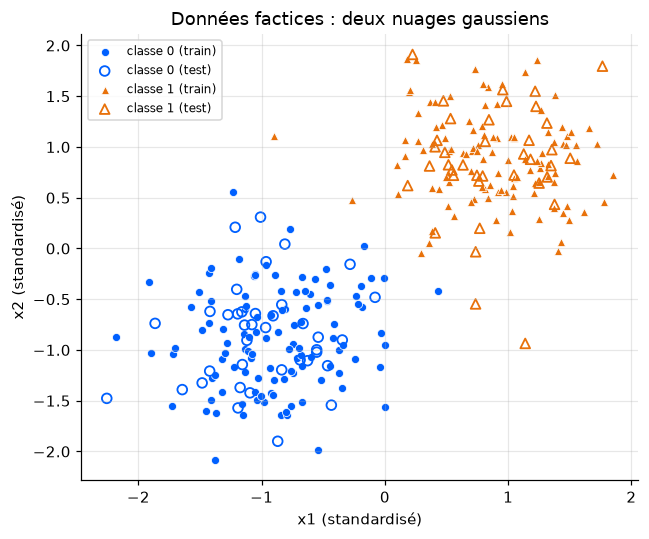

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for classe, couleur, marqueur in [(0, BLEU, "o"), (1, ORANGE, "^")]:
    m = y_train == classe
    ax.scatter(X_train_s[m, 0], X_train_s[m, 1], c=couleur, marker=marqueur, s=28,
               edgecolor="white", linewidth=0.5, label=f"classe {classe} (train)")
    m = y_test == classe
    ax.scatter(X_test_s[m, 0], X_test_s[m, 1], facecolors="none", edgecolors=couleur,
               marker=marqueur, s=40, linewidth=1.2, label=f"classe {classe} (test)")
ax.set_xlabel("x1 (standardisé)"); ax.set_ylabel("x2 (standardisé)")
ax.set_title("Données factices : deux nuages gaussiens")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig("images/donnees_factices.png", dpi=150); plt.show()

**Interprétation :** les deux classes forment deux groupes bien distincts, séparables par une simple droite. C'est le **cas idéal** pour un Perceptron : d'après le théorème de convergence, il doit trouver une frontière qui classe correctement tous les points d'entraînement.

### 7.4 Entraînement et convergence

In [ ]:
model = Perceptron(learning_rate=0.1, n_epochs=50, random_state=42)
model.fit(X_train_s, y_train)

print(model)
print("Poids appris w :", np.round(model.weights_, 4))
print("Biais appris b :", round(model.bias_, 4))
print("Erreurs par époque :", model.errors_)
print(f"Convergé : {model.converged_} (en {model.n_epochs_run_} époques)")

Perceptron(learning_rate=0.1, n_epochs=50, shuffle=True, early_stopping=True, random_state=42)
Poids appris w : [0.1164 0.2025]
Biais appris b : 0.0
Erreurs par époque : [4, 2, 0]
Convergé : True (en 3 époques)


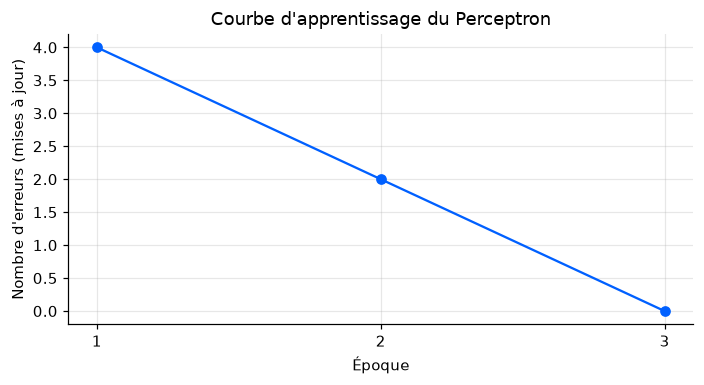

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(1, len(model.errors_) + 1), model.errors_, marker="o", color=BLEU)
ax.set_xlabel("Époque"); ax.set_ylabel("Nombre d'erreurs (mises à jour)")
ax.set_title("Courbe d'apprentissage du Perceptron")
ax.set_xticks(range(1, len(model.errors_) + 1))
plt.tight_layout(); plt.savefig("images/courbe_erreurs.png", dpi=150); plt.show()

**Interprétation :** à la première époque, le Perceptron commet quelques erreurs (ses poids sont presque nuls au départ), puis il corrige sa frontière. Le nombre d'erreurs tombe à **0** en quelques époques : l'algorithme a **convergé** et s'arrête automatiquement (`early_stopping`).

### 7.5 Évaluation sur le jeu de test

On mesure la performance sur des données **jamais vues pendant l'entraînement**. On calcule à la main :
- l'**accuracy** (taux de bonnes prédictions) ;
- la **matrice de confusion** (VN, FP, FN, VP) ;
- la **précision**, le **rappel** et le **F1-score** de la classe 1.

In [ ]:
def evaluer(y_vrai, y_pred):
    # Calcule la matrice de confusion et les métriques principales (classe positive = 1)
    vp = int(np.sum((y_vrai == 1) & (y_pred == 1)))
    vn = int(np.sum((y_vrai == 0) & (y_pred == 0)))
    fp = int(np.sum((y_vrai == 0) & (y_pred == 1)))
    fn = int(np.sum((y_vrai == 1) & (y_pred == 0)))
    accuracy = (vp + vn) / len(y_vrai)
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    rappel = vp / (vp + fn) if (vp + fn) else 0.0
    f1 = 2 * precision * rappel / (precision + rappel) if (precision + rappel) else 0.0
    return {"VN": vn, "FP": fp, "FN": fn, "VP": vp,
            "accuracy": accuracy, "precision": precision, "rappel": rappel, "f1": f1}

res_train = evaluer(y_train, model.predict(X_train_s))
res_test = evaluer(y_test, model.predict(X_test_s))

print(f"{'Métrique':<10} {'Train':>8} {'Test':>8}")
for k in ["accuracy", "precision", "rappel", "f1"]:
    print(f"{k:<10} {res_train[k]:>8.3f} {res_test[k]:>8.3f}")
print("\nMatrice de confusion (test) :")
print(f"            prédit 0   prédit 1")
print(f"réel 0      {res_test['VN']:>8}   {res_test['FP']:>8}")
print(f"réel 1      {res_test['FN']:>8}   {res_test['VP']:>8}")

Métrique      Train     Test
accuracy      1.000    0.974
precision     1.000    1.000
rappel        1.000    0.947
f1            1.000    0.973

Matrice de confusion (test) :
            prédit 0   prédit 1
réel 0            38          0
réel 1             2         36


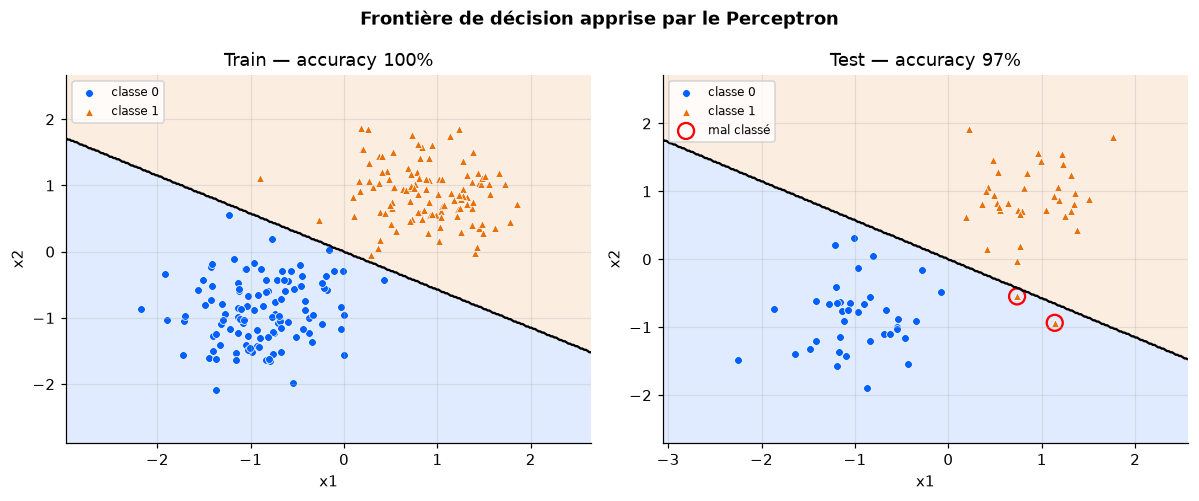

Équation de la frontière : x2 = -0.575 * x1 + -0.000


In [ ]:
def tracer_frontiere(model, X, y, titre, ax, fichier=None):
    # Colore les deux demi-plans prédits et trace la droite w1*x1 + w2*x2 + b = 0
    x_min, x_max = X[:, 0].min() - 0.8, X[:, 0].max() + 0.8
    y_min, y_max = X[:, 1].min() - 0.8, X[:, 1].max() + 0.8
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[BLEU, ORANGE], alpha=0.12)
    ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1.5)
    for classe, couleur, marqueur in [(0, BLEU, "o"), (1, ORANGE, "^")]:
        m = y == classe
        ax.scatter(X[m, 0], X[m, 1], c=couleur, marker=marqueur, s=26,
                   edgecolor="white", linewidth=0.5, label=f"classe {classe}")
    erreurs = model.predict(X) != y
    if erreurs.any():
        ax.scatter(X[erreurs, 0], X[erreurs, 1], s=110, facecolors="none",
                   edgecolors="red", linewidth=1.5, label="mal classé")
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(titre)
    ax.legend(fontsize=8, loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
tracer_frontiere(model, X_train_s, y_train, f"Train — accuracy {res_train['accuracy']:.0%}", axes[0])
tracer_frontiere(model, X_test_s, y_test, f"Test — accuracy {res_test['accuracy']:.0%}", axes[1])
fig.suptitle("Frontière de décision apprise par le Perceptron", fontweight="bold")
plt.tight_layout(); plt.savefig("images/frontiere_decision.png", dpi=150); plt.show()

pente, ordonnee = model.decision_boundary()
print(f"Équation de la frontière : x2 = {pente:.3f} * x1 + {ordonnee:.3f}")

**Interprétation :** la droite noire est la frontière $w_1x_1 + w_2x_2 + b = 0$. Tous les points d'entraînement sont du bon côté (accuracy de 100 % sur le train, comme le prévoit le théorème de convergence). Sur le jeu de test, l'accuracy reste très élevée : le modèle **généralise** à des points qu'il n'a jamais vus. Les 2 points mal classés (entourés en rouge, 2 faux négatifs) sont situés tout près de la frontière : le Perceptron s'arrête à la **première** droite qui sépare le train, et non à la droite « la mieux centrée » entre les deux nuages. C'est l'une des limites présentées en Q6 (frontière non optimale).

### 7.6 Influence du taux d'apprentissage

On compare plusieurs valeurs de $\eta$ sur les mêmes données.

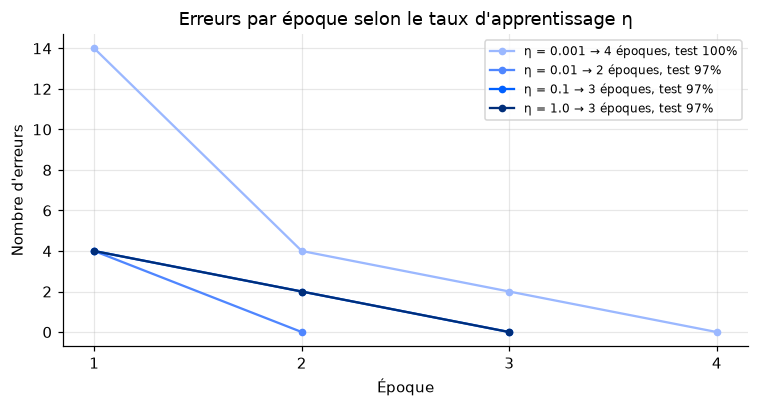

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for eta, couleur in zip([0.001, 0.01, 0.1, 1.0], ["#9BB8FF", "#4F86FF", BLEU, "#002E7A"]):
    m = Perceptron(learning_rate=eta, n_epochs=30, random_state=42).fit(X_train_s, y_train)
    ax.plot(range(1, m.n_epochs_run_ + 1), m.errors_, marker="o", ms=4, color=couleur,
            label=f"η = {eta} → {m.n_epochs_run_} époques, test {m.score(X_test_s, y_test):.0%}")
ax.set_xlabel("Époque"); ax.set_ylabel("Nombre d'erreurs")
ax.set_title("Erreurs par époque selon le taux d'apprentissage η")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/taux_apprentissage.png", dpi=150); plt.show()

**Interprétation :** les courbes η = 0,1 et η = 1 sont superposées. Avec un Perceptron à fonction marche, $\eta$ influence surtout la **vitesse relative** entre l'initialisation aléatoire et les corrections. Lorsque les poids partent de 0, multiplier $\eta$ revient simplement à multiplier $\mathbf{w}$ et $b$ par une constante, ce qui ne change pas la frontière. Avec une initialisation aléatoire, un $\eta$ très petit laisse davantage de poids à cette initialisation au début de l'apprentissage. Dans tous les cas, sur des données séparables, le modèle converge rapidement. Le choix de $\eta$ deviendra beaucoup plus important avec la descente de gradient (ADALINE, réseaux profonds).

### 7.7 Limite n°1 : données qui se chevauchent

On génère maintenant des nuages **plus dispersés** (écart-type 1,6 au lieu de 0,8) : une partie des points se mélangent et **aucune droite ne peut séparer parfaitement** les deux classes.

Convergé : False | époques effectuées : 50
Accuracy train : 0.696 | test : 0.803


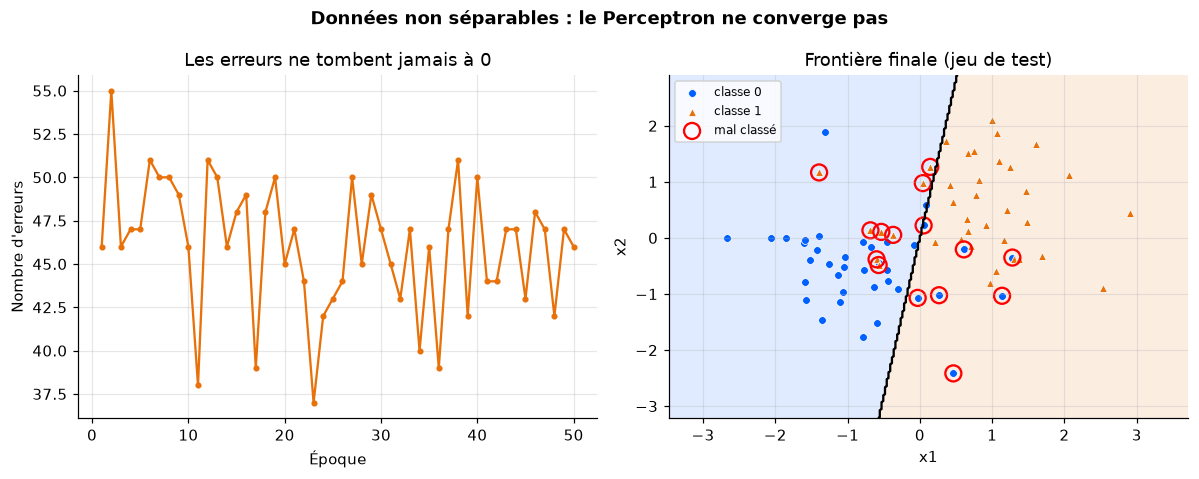

In [ ]:
X_b, y_b = generer_nuages(centre=1.0, ecart_type=1.6, seed=1)
Xb_train, Xb_test, yb_train, yb_test = train_test_split_maison(X_b, y_b, seed=1)
moy_b, std_b = Xb_train.mean(axis=0), Xb_train.std(axis=0)
Xb_train_s, Xb_test_s = (Xb_train - moy_b) / std_b, (Xb_test - moy_b) / std_b

model_b = Perceptron(learning_rate=0.1, n_epochs=50, random_state=42).fit(Xb_train_s, yb_train)
print(f"Convergé : {model_b.converged_} | époques effectuées : {model_b.n_epochs_run_}")
print(f"Accuracy train : {model_b.score(Xb_train_s, yb_train):.3f} | test : {model_b.score(Xb_test_s, yb_test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(range(1, model_b.n_epochs_run_ + 1), model_b.errors_, color=ORANGE, marker=".")
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Nombre d'erreurs")
axes[0].set_title("Les erreurs ne tombent jamais à 0")
tracer_frontiere(model_b, Xb_test_s, yb_test, "Frontière finale (jeu de test)", axes[1])
fig.suptitle("Données non séparables : le Perceptron ne converge pas", fontweight="bold")
plt.tight_layout(); plt.savefig("images/donnees_chevauchement.png", dpi=150); plt.show()

**Interprétation :** la courbe d'erreurs **oscille** sans jamais atteindre 0 : l'algorithme ne converge pas et c'est le **nombre maximal d'époques** qui l'arrête. La frontière finale dépend simplement de la **dernière mise à jour** effectuée : preuve en est, l'accuracy sur le train (environ 70 %) est même **inférieure** à celle du test (environ 80 %), ce qui serait anormal pour un modèle qui aurait réellement optimisé ses paramètres. Le Perceptron n'a **aucun mécanisme** pour garder le meilleur compromis (la variante *Pocket Perceptron* conserve, elle, les meilleurs poids rencontrés). C'est exactement ce que corrigent la régression logistique ou ADALINE, qui minimisent une fonction de coût continue.

### 7.8 Limite n°2 : le problème XOR

La porte **XOR** (« ou exclusif ») renvoie 1 si **une seule** des deux entrées vaut 1. Les points (0,1) et (1,0) sont de classe 1, les points (0,0) et (1,1) de classe 0 : ils sont disposés **en diagonale**, et aucune droite ne peut les séparer.

Prédictions sur les 4 coins : [0 0 0 0] | attendu : [0 1 1 0]
Convergé : False | accuracy : 50%


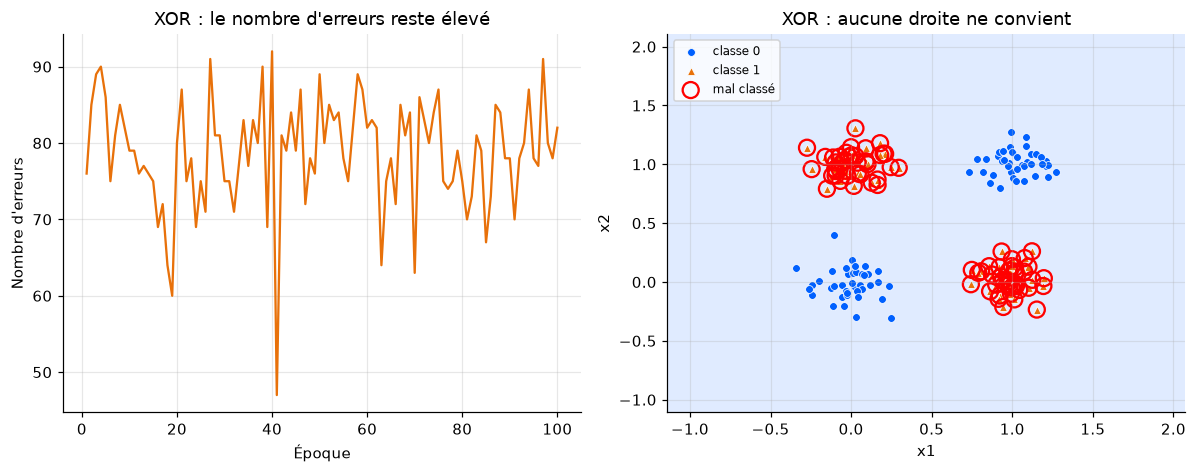

In [ ]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

# On ajoute un peu de bruit autour des 4 coins pour mieux visualiser
rng = np.random.default_rng(3)
X_xor_bruit = np.repeat(X_xor, 40, axis=0) + rng.normal(0, 0.12, size=(160, 2))
y_xor_bruit = np.repeat(y_xor, 40)

p_xor = Perceptron(learning_rate=0.1, n_epochs=100, random_state=42).fit(X_xor_bruit, y_xor_bruit)
print("Prédictions sur les 4 coins :", p_xor.predict(X_xor), "| attendu :", y_xor)
print(f"Convergé : {p_xor.converged_} | accuracy : {p_xor.score(X_xor_bruit, y_xor_bruit):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(range(1, p_xor.n_epochs_run_ + 1), p_xor.errors_, color=ORANGE)
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Nombre d'erreurs")
axes[0].set_title("XOR : le nombre d'erreurs reste élevé")
tracer_frontiere(p_xor, X_xor_bruit, y_xor_bruit, "XOR : aucune droite ne convient", axes[1])
plt.tight_layout(); plt.savefig("images/probleme_xor.png", dpi=150); plt.show()

**Interprétation :** quelle que soit la droite choisie, au moins un des quatre coins se retrouve du mauvais côté. À la fin de l'entraînement, la droite se trouve même ici **en dehors du carré** : le Perceptron prédit 0 pour tous les points et l'accuracy tombe à 50 %, soit le niveau du hasard. La courbe d'erreurs, elle, oscille sans jamais descendre vers 0. C'est la démonstration de **Minsky et Papert (1969)** : un Perceptron seul ne peut pas résoudre XOR.

**Solution (non implémentée ici) :** ajouter une **couche cachée** (Perceptron multicouche). Par exemple, $\text{XOR}(x_1, x_2) = \text{AND}\big(\text{OR}(x_1, x_2),\ \text{NAND}(x_1, x_2)\big)$ : deux neurones dans la couche cachée, un neurone en sortie. C'est le point de départ du Deep Learning.

### 7.9 Robustesse : répétition sur plusieurs tirages aléatoires

Un seul tirage peut être chanceux. On répète l'expérience sur **20 jeux de données factices** générés avec des graines différentes, pour vérifier que les résultats sont stables.

In [ ]:
scores, epoques, convergences = [], [], []
for seed in range(20):
    Xs, ys = generer_nuages(seed=seed)
    Xtr, Xte, ytr, yte = train_test_split_maison(Xs, ys, seed=seed)
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
    m = Perceptron(learning_rate=0.1, n_epochs=50, random_state=seed).fit((Xtr - mu) / sd, ytr)
    scores.append(m.score((Xte - mu) / sd, yte)); epoques.append(m.n_epochs_run_); convergences.append(m.converged_)

scores = np.array(scores)
print(f"Accuracy test sur 20 tirages : moyenne {scores.mean():.3f} | écart-type {scores.std():.3f} | min {scores.min():.3f}")
print(f"Tirages ayant convergé (0 erreur sur une époque) : {sum(convergences)} / 20")
ep_conv = [e for e, c in zip(epoques, convergences) if c]
print(f"Époques nécessaires quand il y a convergence : médiane {np.median(ep_conv):.0f} | max {max(ep_conv)}")

Accuracy test sur 20 tirages : moyenne 0.995 | écart-type 0.010 | min 0.961
Tirages ayant convergé (0 erreur sur une époque) : 16 / 20
Époques nécessaires quand il y a convergence : médiane 2 | max 41


**Interprétation :** sur 20 jeux de données différents, l'accuracy de test reste très élevée (environ 99 % en moyenne) avec un faible écart-type : notre implémentation est **fiable et stable**.

Point intéressant : quelques tirages **ne convergent pas**. Une loi normale produit parfois des points extrêmes : il suffit d'un ou deux points d'une classe « égarés » dans le nuage de l'autre classe pour que les données ne soient **plus parfaitement séparables**. Le Perceptron s'arrête alors au nombre maximal d'époques, tout en gardant une très bonne accuracy. On retrouve, à petite échelle, la limite vue en 7.7 : sur des données réelles, qui sont rarement parfaitement séparables, il faudra toujours fixer un nombre maximal d'époques.

---
# 3. Conclusion

### Ce que nous avons appris

- Le **Deep Learning** est un sous-ensemble du **Machine Learning** fondé sur des réseaux de neurones à plusieurs couches. Il excelle sur les données non structurées et volumineuses. Le ML classique reste préférable pour des données tabulaires de taille modeste, quand l'interprétabilité compte.
- Le **Perceptron** est la brique élémentaire de ces réseaux : une **somme pondérée** des entrées, un **biais**, puis une **fonction de seuil** (Heaviside). Il apprend en corrigeant ses poids **uniquement lorsqu'il se trompe**.

### Ce que nos expériences montrent

| Expérience | Résultat | Conclusion |
|---|---|---|
| Porte AND | Convergence en quelques époques | L'implémentation est correcte |
| Nuages séparables | Accuracy de 100 % sur le train, très élevée sur le test | Le Perceptron généralise bien quand les classes sont linéairement séparables |
| 20 tirages aléatoires | Résultats stables | L'implémentation est robuste |
| Nuages qui se chevauchent | Pas de convergence, les erreurs oscillent | Limite : aucun critère d'optimalité si les données ne sont pas séparables |
| XOR | Échec | Limite fondamentale : séparation linéaire uniquement |

### Transition vers la suite du projet

La classe `Perceptron` étant validée, l'étape suivante consistera à l'appliquer à un **problème réel de santé** : le jeu de données *Breast Cancer Wisconsin* (569 tumeurs, 30 variables, diagnostic bénin / malin). Il faudra alors réaliser une analyse exploratoire, réduire la dimension, et choisir des métriques adaptées au contexte médical, où un **faux négatif** (tumeur maligne non détectée) est bien plus grave qu'un faux positif.